In [1]:
import numpy

In [2]:
with open("data/sample.tir") as f:
    lines = f.readlines()

In [3]:
with open("data/sample.tir") as f:
    lines = f.readlines()

print(len(lines))
for line in lines[:40]:
    print(line, end="")

257
[MDI_HEADER]
FILE_TYPE                ='tir'
FILE_VERSION             = 3.0
FILE_FORMAT              ='ASCII'
! : TIRE_VERSION :      MF61
! : COMMENT :      Example tyre data file with Pacejka coefficients
! : COMMENT :      225/50R17

$----------------------------------------------------------------units
[UNITS]
 LENGTH              = 'meter'
 FORCE               = 'Newton'
 ANGLE               = 'radians'
 MASS                = 'kg'
 TIME                = 'second'
$-----------------------------------------------------------------model
[MODEL]
FITTYP                   = 61
USE_MODE                 = 14                       $Tyre use switch (IUSED)
VXLOW                    = 1
LONGVL                   = 16.7                     $Measurement speed
TYRESIDE                 = 'Left'                   $Mounted side of tyre at vehicle/test bench
$------------------------------------------------------------dimensions
[DIMENSION]
UNLOADED_RADIUS          = 0.3135                   $Free

In [4]:
with open("data/sample.tir") as f:
    lines = f.readlines()

print(len(lines))
for line in lines[40:80]:
    print(line, end="")

257
BELT_IYY                 = 0.55              $Belt polar moment of inertia
GRAVITY                  = -9.81             $Gravity acting on belt in Z direction
$-------------------------------------------------------------parameter
[VERTICAL]
FNOMIN                   = 4000                     $Nominal wheel load
VERTICAL_STIFFNESS       = 209651                   $Tyre vertical stiffness
VERTICAL_DAMPING         = 50                       $Tyre vertical damping
BREFF                    = 8.386                    $Low load stiffness e.r.r.
DREFF                    = 0.25826                  $Peak value of e.r.r.
FREFF                    = 0.07394                  $High load stiffness e.r.r.
BOTTOM_OFFST             = 0.01                     $Distance to rim when bottoming starts to occur
BOTTOM_STIFF             = 3.0e+06                  $Vertical stiffness of bottomed tyre
$---------------------------------------------inflation_pressure_range
[INFLATION_PRESSURE_RANGE]
PRESMIN   

In [5]:
for i, line in enumerate(lines):
    if "UNLOADED_RADIUS" in line:
        print(i, line)

24 UNLOADED_RADIUS          = 0.3135                   $Free tyre radius



In [6]:

print(len(lines))
for line in lines[24:30]:
    print(line, end="")

257
UNLOADED_RADIUS          = 0.3135                   $Free tyre radius
WIDTH                    = 0.205                    $Nominal section width of the tyre
ASPECT_RATIO             = 0.60                     $Nominal aspect ratio
RIM_RADIUS               = 0.1905                   $Nominal rim radius
RIM_WIDTH                = 0.195                    $Rim width
$----------------------------------------------------operating conditions


In [7]:
line = "UNLOADED_RADIUS          = 0.3135                  $Free tyre radius"

clean = line.split("$")[0].strip()
print(repr(clean))

key, value = clean.split("=")
print(repr(key.strip()), repr(value.strip()))

'UNLOADED_RADIUS          = 0.3135'
'UNLOADED_RADIUS' '0.3135'


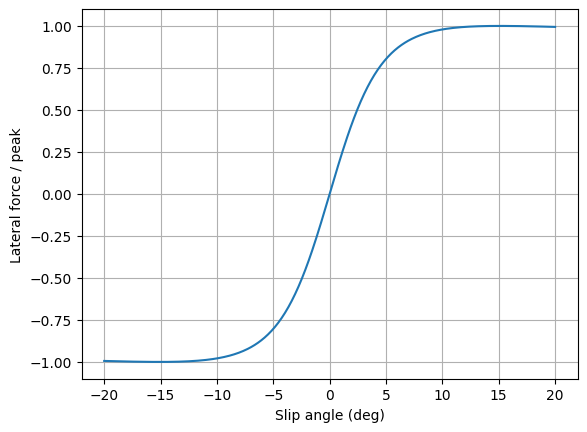

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def magic_formula(x, B, C, D, E):
    Bx = B * x
    return D * np.sin(C * np.arctan(Bx - E * (Bx - np.arctan(Bx))))

alpha_deg = np.linspace(-20, 20, 400)
alpha = np.radians(alpha_deg)

y = magic_formula(alpha, B=10, C=1.3, D=1.0, E=0.0)

plt.plot(alpha_deg, y)
plt.xlabel("Slip angle (deg)")
plt.ylabel("Lateral force / peak")
plt.grid(True)
plt.show()

In [1]:
line = "PDY1 = 0.8785 $Lateral friction Muy"

clean = line.split("$")[0].strip()
print(repr(clean))

key, value = clean.split("=")
print(repr(key.strip()), repr(value.strip()))

'PDY1 = 0.8785'
'PDY1' '0.8785'


In [2]:
number = float(value.strip())
print(number, type(number))
print(number * 2)

0.8785 <class 'float'>
1.757


In [3]:
float("'meter'")

ValueError: could not convert string to float: "'meter'"

In [4]:
def parse_value(text):
    text = text.strip()
    try:
        return float(text)
    except ValueError:
        return text.strip("'")

print(parse_value(" 0.8785 "))
print(parse_value("'meter'"))
print(parse_value("-15.324"))
print(parse_value("3.0e+06"))

0.8785
meter
-15.324
3000000.0


In [5]:
params = {}

with open("data/sample.tir") as f:
    for line in f:
        line = line.split("$")[0].strip()

        if line == "" or line.startswith("!"):
            continue
        if line.startswith("["):
            continue

        key, value = line.split("=")
        params[key.strip()] = parse_value(value)

print(len(params))
print(params["PDY1"])
print(params["UNLOADED_RADIUS"])
print(params["TYRESIDE"])

215
0.8785
0.3135
Left


In [6]:
def load_tir(path):
    params = {}
    section = None

    with open(path) as f:
        for line in f:
            line = line.split("$")[0].strip()

            if line == "" or line.startswith("!"):
                continue

            if line.startswith("["):
                section = line.strip("[]")
                params[section] = {}
                continue

            key, value = line.split("=")
            params[section][key.strip()] = parse_value(value)

    return params


tyre = load_tir("data/sample.tir")

print(list(tyre.keys()))
print(tyre["UNITS"]["MASS"], tyre["INERTIA"]["MASS"])
print(tyre["LATERAL_COEFFICIENTS"]["PDY1"])

['MDI_HEADER', 'UNITS', 'MODEL', 'DIMENSION', 'OPERATING_CONDITIONS', 'INERTIA', 'VERTICAL', 'INFLATION_PRESSURE_RANGE', 'LONG_SLIP_RANGE', 'SLIP_ANGLE_RANGE', 'INCLINATION_ANGLE_RANGE', 'VERTICAL_FORCE_RANGE', 'SCALING_COEFFICIENTS', 'LONGITUDINAL_COEFFICIENTS', 'LATERAL_COEFFICIENTS', 'OVERTURNING_COEFFICIENTS', 'ROLLING_COEFFICIENTS', 'ALIGNING_COEFFICIENTS', 'LOADED_RADIUS_COEFFICIENTS']
kg 9.3
0.8785


In [7]:
def parse_value(text):
    text = text.strip()
    try:
        return float(text)
    except ValueError:
        return text.strip("'")


def load_tir(path):
    params = {}
    section = None

    with open(path) as f:
        for line in f:
            line = line.split("$")[0].strip()

            if line == "" or line.startswith("!"):
                continue

            if line.startswith("["):
                section = line.strip("[]")
                params[section] = {}
                continue

            key, value = line.split("=")
            params[section][key.strip()] = parse_value(value)

    return params